# BatChat vs the crowd: where Batman fans disagree

*Red Rain* is **#6** on BatChat's list, but Goodreads readers give it only **3.66/5**. *White Knight* gets a glowing **4.28/5** on Goodreads, while BatChat puts it at **#734** of 740. [Goodreads: Red Rain](https://www.goodreads.com/book/show/72479.Batman_Dracula) · [White Knight](https://www.goodreads.com/book/show/37775321-batman)

[BatChat](https://comicsxf.com/batchat-rankings/) is a podcast where **Matt Lazorwitz and Will Nevin** have read and ranked 740 Batman stories. Which other books split them from everyone else? And do they side more with readers or with critics?

We compare their 740 rankings with **Goodreads** (reader star ratings for collected books) and **Comic Book RoundUp** (a site that gathers critic reviews and reader scores for single issues). On BatChat, #1 is best; on Goodreads and RoundUp, a higher score is better. Snapshot: **21 October 2026**.

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ). New here? Start with [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories)*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import bootstrap, spearmanr

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv")
N = len(stories)
# Flip ranks so that, like the outside ratings, higher means "more liked".
stories["preference"] = N - stories["rank"]


def spearman_interval(x, y):
    """95% bootstrap interval for the Spearman correlation of paired values."""
    result = bootstrap(
        (np.asarray(x), np.asarray(y)),
        lambda a, b: spearmanr(a, b).statistic,
        paired=True,
        vectorized=False,
        n_resamples=1000,
        method="percentile",
        random_state=42,
    )
    return result.confidence_interval

## 1. First, make sure we compare the same comic

*Ego and Other Tails* is a collection that bundles the short *Ego* with other stories. The first *Court of Owls* paperback collects only part of the arc the podcast ranked. Ratings like these are for a different book, so they don't count.

A Goodreads match must be the same story. A RoundUp match must cover every issue, and the issue can't also contain a different story, since RoundUp scores whole issues. Minimums: 100 Goodreads ratings; 5 RoundUp reader ratings per issue; 3 critic reviews per issue.

That leaves a small slice of the list:

In [2]:
goodreads_ok = stories.goodreads_match_scope.eq("same_story") & stories.goodreads_rating_count.ge(
    100
)
roundup_ok = stories.roundup_narrative_scope.eq("all_indexed_narratives")
audiences = {
    "Goodreads readers": ("goodreads_rating", goodreads_ok),
    "RoundUp readers": (
        "roundup_user_rating",
        roundup_ok & stories.roundup_user_complete & stories.roundup_user_min_count.ge(5),
    ),
    "RoundUp critics": (
        "roundup_critic_rating",
        roundup_ok & stories.roundup_critic_complete & stories.roundup_critic_min_count.ge(3),
    ),
}
cohorts = {label: stories[ok] for label, (_, ok) in audiences.items()}
pd.DataFrame(
    {
        "Found a rating": [stories[score].notna().sum() for score, _ in audiences.values()],
        "Passed the same-story check": [len(c) for c in cohorts.values()],
        "Their median BatChat rank": [c["rank"].median() for c in cohorts.values()],
    },
    index=audiences.keys(),
)

,Found a rating,Passed the same-story check,Their median BatChat rank
Goodreads readers,55,40,113.5
RoundUp readers,326,110,245.0
RoundUp critics,174,78,282.5


The Goodreads books lean toward BatChat's favorites (half of them rank above #114): famous books get more ratings, and the hosts like a lot of famous books. RoundUp covers a wider, less favored selection.

## 2. Which books divide BatChat and Goodreads?

Put **the same 40 books** in order twice: once by BatChat rank, once by Goodreads rating. Then look for the books that move the most.

**Farther right means more liked.** Blue is BatChat; orange is Goodreads. Look for the longest lines: those are the books the two audiences disagree on most.

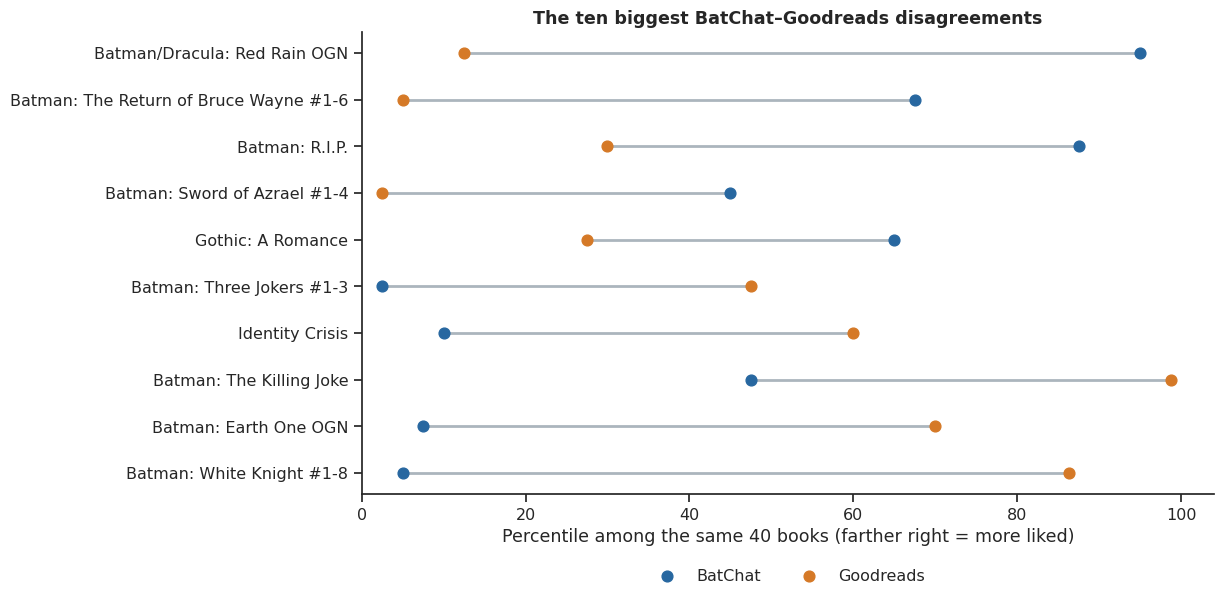

In [3]:
score, _ = audiences["Goodreads readers"]
goodreads = cohorts["Goodreads readers"].assign(
    BatChat=lambda d: d.preference.rank(pct=True) * 100,
    Goodreads=lambda d: d[score].rank(pct=True) * 100,
)
goodreads["gap"] = goodreads.BatChat - goodreads.Goodreads
shown = pd.concat([goodreads.nlargest(5, "gap"), goodreads.nsmallest(5, "gap")]).sort_values("gap")

fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(shown.title, shown.BatChat, shown.Goodreads, color="#ABB5BD", lw=2)
ax.scatter(shown.BatChat, shown.title, color=BLUE, label="BatChat", s=60, zorder=3)
ax.scatter(shown.Goodreads, shown.title, color=ORANGE, label="Goodreads", s=60, zorder=3)
ax.set(
    xlabel=f"Percentile among the same {len(goodreads)} books (farther right = more liked)",
    title="The ten biggest BatChat–Goodreads disagreements",
    xlim=(0, 104),
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
plt.show()

*Red Rain* sits near the top for BatChat and near the bottom for Goodreads. *White Knight* is the mirror image.

Both books reinvent Batman's world: Doug Moench and Kelley Jones turn him into a vampire, and Sean Murphy makes a supposedly reformed Joker his political rival. So "the hosts dislike unconventional Batman" doesn't explain it. My guess: *Red Rain* is a 1991 Elseworlds book with Kelley Jones's gothic art, which a podcast steeped in Bronze Age Batman loves and a Goodreads reader coming from the *Arkham* games may find dated; *White Knight* is the reverse. The ratings only show *where* the audiences disagree, though, not *why*. [DC: Red Rain](https://www.dc.com/graphic-novels/batman-and-dracula-trilogy-1991/tales-of-the-multiverse-batman-vampire) · [White Knight](https://www.dc.com/blog/2017/07/07/sean-murphy-s-batman-white-knight-arrives-october-4)

*The Return of Bruce Wayne* (BatChat **#53**) is the other big BatChat-only favorite.

## 3. Is there much agreement overall?

Some. Three panels below, one per outside source; **each dot is one story**. Better-rated books tend to rank higher on BatChat, but with plenty of scatter.

The number under each panel is a Spearman correlation: how similarly two lists are ordered. **1 means the same order, 0 means no relationship.** The range after it is a 95% interval, a rough measure of how uncertain that number is.

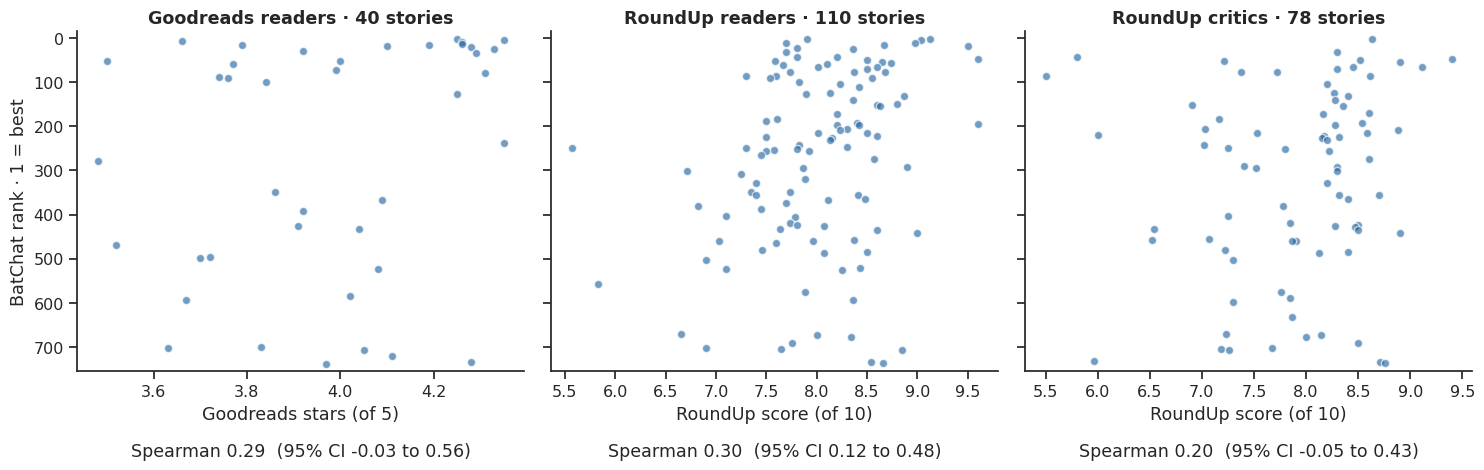

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (label, frame) in zip(axes, cohorts.items()):
    ratings = frame[audiences[label][0]]
    rho = spearmanr(frame.preference, ratings).statistic
    ci = spearman_interval(frame.preference, ratings)
    ax.scatter(ratings, frame["rank"], s=35, alpha=0.65, color=BLUE, edgecolors="white")
    ax.set(
        title=f"{label} · {len(frame)} stories",
        xlabel="Goodreads stars (of 5)"
        if label.startswith("Goodreads")
        else "RoundUp score (of 10)",
        ylim=(N + 15, -15),
    )
    ax.text(
        0.5,
        -0.25,
        f"Spearman {rho:.2f}  (95% CI {ci.low:.2f} to {ci.high:.2f})",
        transform=ax.transAxes,
        ha="center",
    )
axes[0].set_ylabel("BatChat rank · 1 = best")
fig.tight_layout()
plt.show()

RoundUp readers agree most with BatChat (**0.30**), then Goodreads (**0.29**) and critics (**0.20**). With this few books, though, those three numbers are basically a tie, and every panel contains different books. Let's give everyone the same list.

## 4. Readers or critics? Hold the books fixed

**69 stories** have enough reader *and* critic ratings on RoundUp. Below: the top five rows are books critics liked more than readers, the bottom five the reverse. Both use a ten-point scale.

In [5]:
paired = stories[audiences["RoundUp readers"][1] & audiences["RoundUp critics"][1]].copy()
paired["critics_minus_readers"] = paired.roundup_critic_rating - paired.roundup_user_rating
pd.concat(
    [paired.nlargest(5, "critics_minus_readers"), paired.nsmallest(5, "critics_minus_readers")]
)[
    ["title", "rank", "roundup_critic_rating", "roundup_user_rating", "critics_minus_readers"]
].set_axis(["Story", "BatChat rank", "Critics", "Readers", "Critics − readers"], axis=1).set_index(
    "Story"
).round(2)

,BatChat rank,Critics,Readers,Critics − readers
Story,,,,
Being Robin,250,7.25,5.57,1.68
Shadows,302,8.30,6.72,1.58
Batman: Black and White V.4,87,8.62,7.30,1.32
Sharkbite,356,8.70,7.40,1.30
Mindfields,380,7.78,6.82,0.95
Slay Ride,42,5.80,8.20,-2.40
The Clown at Midnight,85,5.50,7.60,-2.10
Batman and Son,458,6.52,8.38,-1.85
Blackest Knight,152,6.90,8.60,-1.70


Readers give *Slay Ride* (Paul Dini and Don Kramer's Joker-in-a-car one-shot) **8.2** and critics **5.8**; BatChat ranks it **#42**. Readers also prefer *The Clown at Midnight*, Grant Morrison and John Van Fleet's illustrated prose story, **7.6 to 5.5**; BatChat puts it at **#85**. So on these two, the hosts side with the readers.

Across all 69 stories, though, **the hosts march to their own beat**: BatChat agrees only weakly with readers (0.18) and critics (0.16), while readers and critics agree much more with each other (0.44).

In [6]:
agreement = pd.Series(
    {
        "BatChat vs readers": spearmanr(paired.preference, paired.roundup_user_rating).statistic,
        "BatChat vs critics": spearmanr(paired.preference, paired.roundup_critic_rating).statistic,
        "Readers vs critics": spearmanr(
            paired.roundup_user_rating, paired.roundup_critic_rating
        ).statistic,
    }
)
print(agreement.round(2).to_string())

BatChat vs readers    0.18
BatChat vs critics    0.16
Readers vs critics    0.44


## 5. The surprise: readers love the old books, critics the new ones

For 2000s stories, readers score about **0.85 points higher** than critics. By the 2020s, critics score **0.48 higher**. The chart shows critic score minus reader score for each story, by decade: above zero, critics liked it more; below zero, readers did.

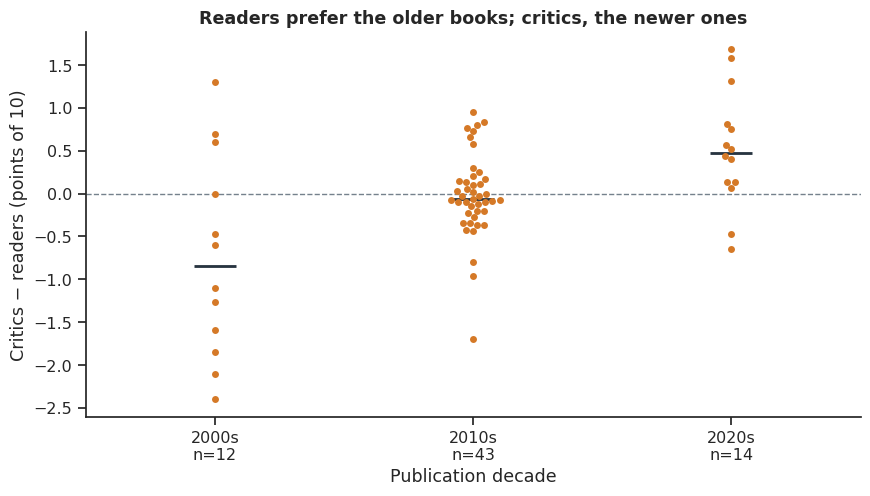

Publication year vs the critic–reader gap: Spearman 0.55 (95% interval 0.32 to 0.76); dropping any one story keeps it between 0.53 and 0.60.


In [7]:
paired["decade"] = (paired.cover_year_start // 10 * 10).astype(int).astype(str) + "s"
order = sorted(paired.decade.unique())
fig, ax = plt.subplots(figsize=(10, 5))
sns.swarmplot(
    data=paired, x="decade", y="critics_minus_readers", order=order, color=ORANGE, size=5, ax=ax
)
sns.pointplot(
    data=paired,
    x="decade",
    y="critics_minus_readers",
    order=order,
    estimator="median",
    errorbar=None,
    linestyle="none",
    markers="_",
    markersize=30,
    color="#273440",
    ax=ax,
)
ax.axhline(0, color=GREY, lw=1, ls="--")
ax.set_xticks(range(len(order)), [f"{d}\nn={(paired.decade == d).sum()}" for d in order])
ax.set(
    xlabel="Publication decade",
    ylabel="Critics − readers (points of 10)",
    title="Readers prefer the older books; critics, the newer ones",
)
plt.show()

year_rho = spearmanr(paired.cover_year_start, paired.critics_minus_readers).statistic
ci = spearman_interval(paired.cover_year_start, paired.critics_minus_readers)
leave_one_out = [
    spearmanr(*paired.drop(i)[["cover_year_start", "critics_minus_readers"]].to_numpy().T).statistic
    for i in paired.index
]
print(
    f"Publication year vs the critic–reader gap: Spearman {year_rho:.2f} "
    f"(95% interval {ci.low:.2f} to {ci.high:.2f}); dropping any one story keeps it between "
    f"{min(leave_one_out):.2f} and {max(leave_one_out):.2f}."
)

That link with publication year is fairly strong and doesn't hinge on any one book. One likely reason: readers find an older comic long after the reviews, often *because* it's already a classic.

## Takeaways

- The clearest disagreements are about particular books: *Red Rain* and *The Return of Bruce Wayne* do unusually well on BatChat, and *White Knight* unusually badly.
- Hold the books fixed and BatChat sides with neither readers nor critics. The hosts have their own taste.
- Readers favor older comics more than critics do, and the gap flips for recent ones.

If you've read *Red Rain* and *White Knight*, where would you put them? Is it the premise, the art, or what each story thinks Batman should be?

**More BatChat notebooks:** [What pushes a Batman story up BatChat's list?](https://www.kaggle.com/code/danofer/what-pushes-a-batman-story-up-batchat-s-list) · [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you enjoyed this, an upvote helps other Batman fans find it.